Q21. Generate synthetic data with 4 centers using make_blobs and apply K-Means clustering. Visualize using a scatter plot.

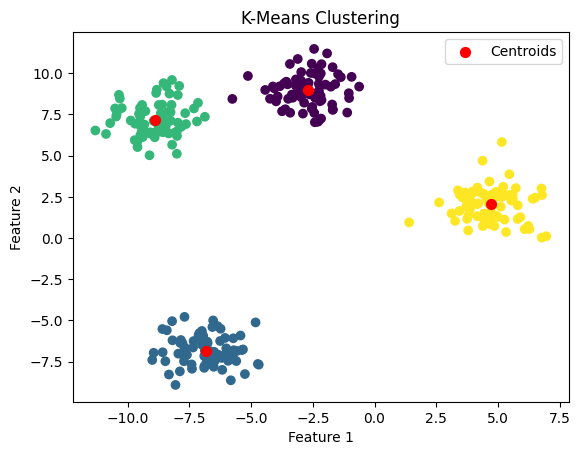

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, y = make_blobs(
    n_samples = 300,
    centers = 4,
    random_state=42
)

model = KMeans(n_clusters=4, random_state=40)
labels = model.fit_predict(X)

plt.scatter(X[:, 0], X[:,1], c=labels, cmap="viridis")
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    marker=".", s=200, color="r", label="Centroids"
)
plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

Explanation: make_blobs() generates four groups of synthetic data. K-Means assigns each point to one of four clusters, and the scatter plot displays the clusters and their centroids.

Q22. Load the Iris dataset and use Agglomerative Clustering to group the data into 3 clusters. Display the first 10 predicted labels.

In [2]:
from sklearn.datasets import load_iris
from sklearn.cluster import AgglomerativeClustering

data = load_iris()
X = data.data

model = AgglomerativeClustering(n_clusters=3)
labels = model.fit_predict(X)

print(f"First 10 predicted labels: ")
print(labels[:10])

First 10 predicted labels: 
[1 1 1 1 1 1 1 1 1 1]


Explanation: Agglomerative Clustering starts with individual data points and repeatedly merges the closest clusters until three clusters remain.

Q23. Generate synthetic data using make_moons and apply DBSCAN. Highlight outliers in the plot.

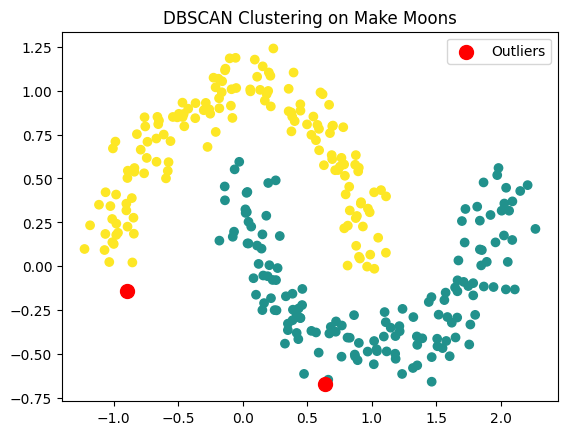

Noise points: 2


In [3]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

X, y = make_moons(
    n_samples=300,
    noise=0.1,
    random_state=42
)

X_scaled = StandardScaler().fit_transform(X)

model = DBSCAN(eps=0.3, min_samples=5)
labels = model.fit_predict(X_scaled)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")

noise = labels == -1  # noise: This variable stores a boolean array of True and False values, where True indicates sample is an outlier/noise point.
plt.scatter(
    X[noise, 0], X[noise, 1],
    color="red", marker="o", s=100,
    label="Outliers"
)

plt.title("DBSCAN Clustering on Make Moons")
plt.legend()
plt.show()

print("Noise points:", sum(noise))

Explanation: DBSCAN identifies dense regions as clusters and assigns isolated points the label -1. Red crosses represent the detected noise points.

Q24. Load the Wine dataset and apply K-Means clustering after standardizing the features. Print the size of each cluster.

In [4]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import numpy as np

data = load_wine()
X = data.data

X_scaled = StandardScaler().fit_transform(X)

# What n_init=10 does: The algorithm will run 10 separate times, each starting with a different set of initial centroids.
# It then selects the single run that results in the lowest inertia (the sum of squared distances of samples to their
# closest cluster center) as the final clustering model.

model = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = model.fit_predict(X_scaled)

unique, counts = np.unique(labels, return_counts=True)

for cluster, count in zip(unique, counts):
    print(f"Cluster {cluster}: {count} samples")

Cluster 0: 65 samples
Cluster 1: 51 samples
Cluster 2: 62 samples


Explanation: The Wine dataset contains numerical features with different scales. StandardScaler brings them to a comparable scale before K-Means clustering.

Q25. Use make_circles to generate synthetic data and cluster it using DBSCAN. Plot the result.

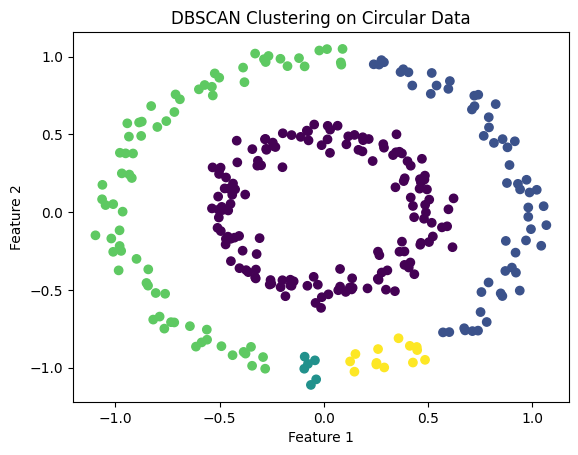

In [5]:
from sklearn.datasets import make_circles

X, y = make_circles(
    n_samples=300,
    factor=0.5,
    noise=0.05,
    random_state=42
)

# eps: It acts as a threshold; if the distance between two points is less than or equal to $0.15$$0.15$, they are considered neighbors.
# min_samples: This specifies the minimum number of data points (including the point itself) that must fall within the eps neighborhood.
# If a point has fewer than 5 neighbors and is not close to any core point, it is labeled as noise/outlier (represented by -1).
model = DBSCAN(eps=0.15, min_samples=5)
labels = model.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.title("DBSCAN Clustering on Circular Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Explanation: DBSCAN can identify circular and non-spherical clusters because it groups points based on density rather than distance from centroids.

Q26. Load the Breast Cancer dataset, apply MinMaxScaler, and use K-Means with 2 clusters. Output the cluster centroids.

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import MinMaxScaler

data = load_breast_cancer()
X = data.data

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

model = KMeans(n_clusters=2, random_state=42, n_init=10)
model.fit(X_scaled)

print("Cluster Centroids:")
print(model.cluster_centers_)

Cluster Centroids:
[[0.50483563 0.39560329 0.50578661 0.36376576 0.46988732 0.42226302
  0.41838662 0.46928035 0.45899738 0.29945886 0.19093085 0.19112073
  0.17903433 0.13086432 0.18017962 0.25890126 0.12542475 0.30942779
  0.190072   0.13266975 0.48047448 0.45107371 0.4655302  0.31460597
  0.49868817 0.36391461 0.39027292 0.65827197 0.33752296 0.26041387]
 [0.25535358 0.28833455 0.24696416 0.14388369 0.35743076 0.18019471
  0.10344776 0.1306603  0.34011829 0.25591606 0.06427485 0.18843043
  0.05975663 0.02870108 0.18158628 0.13242941 0.05821528 0.18069336
  0.17221057 0.08403996 0.2052406  0.32069002 0.19242138 0.09943446
  0.3571115  0.14873935 0.13142287 0.26231363 0.22639412 0.15437354]]


Explanation: MinMaxScaler scales all features between 0 and 1. K-Means divides the dataset into two clusters and calculates their centroids.

Q27. Generate synthetic data using make_blobs with varying cluster standard deviations and cluster with DBSCAN.

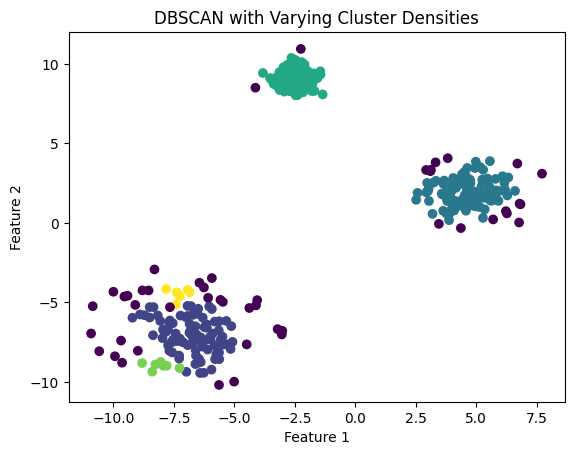

Clusters: 5
Noise points: 47


In [7]:
X, y = make_blobs(
    n_samples=400,
    centers=3,
    cluster_std=[0.5, 1.0, 1.5],
    random_state=42
)

model = DBSCAN(eps=0.6, min_samples=5)
labels = model.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.title("DBSCAN with Varying Cluster Densities")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

print("Clusters:", len(set(labels)) - (1 if -1 in labels else 0))
print("Noise points:", sum(labels == -1))

Explanation: The dataset contains clusters with different levels of spread. DBSCAN attempts to identify dense regions, although one global eps value may not work equally well for every cluster.

Q28. Load the Digits dataset, reduce it to 2D using PCA, and visualize clusters from K-Means.

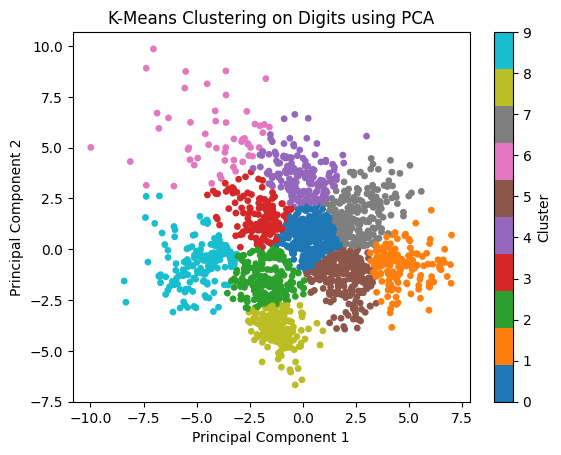

In [8]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

data = load_digits()
X = data.data

X_scaled = StandardScaler().fit_transform(X)

X_pca = PCA(n_components=2).fit_transform(X_scaled)

model = KMeans(n_clusters=10, random_state=42, n_init=10)
labels = model.fit_predict(X_pca)

plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels, cmap="tab10", s=15
)

plt.title("K-Means Clustering on Digits using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

Explanation: PCA reduces the 64 original pixel features to two components. K-Means then groups the transformed data into ten clusters for visualization.

Q29. Create synthetic data using make_blobs and evaluate Silhouette Scores for K = 2 to 5. Display as a bar chart.

K=2, Silhouette Score=0.5902
K=3, Silhouette Score=0.7569
K=4, Silhouette Score=0.7916
K=5, Silhouette Score=0.6890


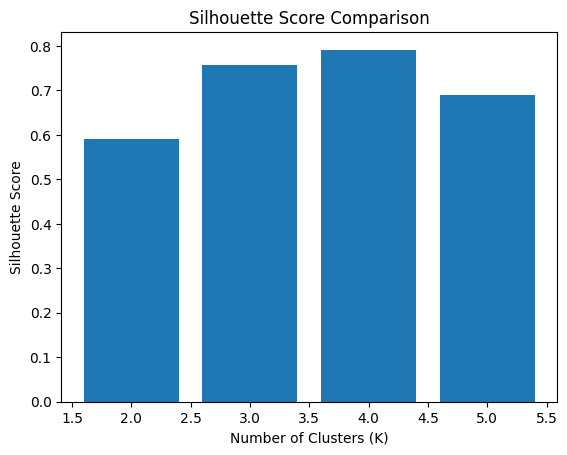

In [9]:
from sklearn.metrics import silhouette_score

X, y = make_blobs(
    n_samples=300,
    centers=4,
    random_state=42
)

scores = []

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)

    # (b-a)/(max(a,b)) where: a is internal distances & b is distances to other groups
    score = silhouette_score(X, labels)
    scores.append(score)

    print(f"K={k}, Silhouette Score={score:.4f}")

plt.bar([2, 3, 4, 5], scores)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")
plt.show()

Explanation: The program calculates the Silhouette Score for four different K values. The highest score(K=4) indicates the best separation and cohesion among the tested solutions.

Q30. Load the Iris dataset and use hierarchical clustering to group data. Plot a dendrogram with average linkage.

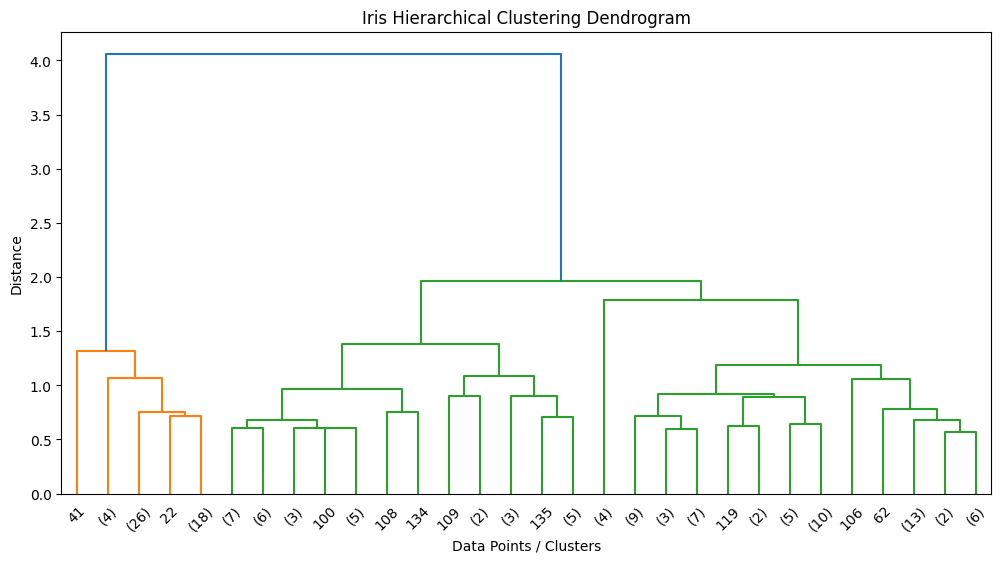

In [10]:
from sklearn.datasets import load_iris
# Hierarchical clustering: "linkage" computes the step-by-step grouping of your data points
                         # "dendrogram" draws the tree diagram showing those groupings.
from scipy.cluster.hierarchy import dendrogram, linkage

data = load_iris()
X = data.data

Z = linkage(X, method="average")

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode="lastp", p=30)

plt.title("Iris Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points / Clusters")
plt.ylabel("Distance")
plt.show()

Explanation: Average linkage calculates the average distance between all pairs of observations in two clusters. The dendrogram displays the merging process.

Q31. Generate synthetic data with overlapping clusters using make_blobs, then apply K-Means and visualize with decision boundaries.

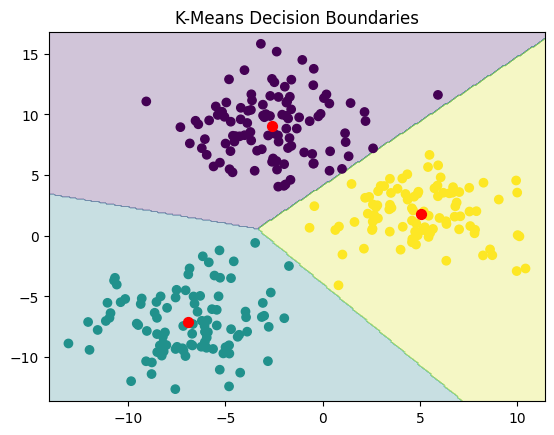

In [11]:
X, y = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=2.5,
    random_state=42
)

model = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = model.fit_predict(X)

xx, yy = np.meshgrid(
    # np.linspace(min - 1, max + 1, 300): Creates 300 evenly spaced numbers spanning from slightly below the minimum value of a feature to slightly above its maximum value.
    # np.meshgrid(...): Takes these two 1D coordinate arrays and replicates them to construct a coordinate grid.
    np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 300),
    np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 300)
)

# xx.ravel() and yy.ravel(): Flattens the $300 \times 300$$300 \times 300$ 2D grids into 1D arrays of $90,000$$90,000$ elements.
grid = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.25)
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    marker=".", color="red", s=200
)

plt.title("K-Means Decision Boundaries")
plt.show()

Explanation: The decision regions show which centroid is closest to each location in the feature space. Overlapping data points may be assigned to different clusters despite their proximity.

Q32. Load the Digits dataset and apply DBSCAN after reducing dimensions with t-SNE. Visualize the results.

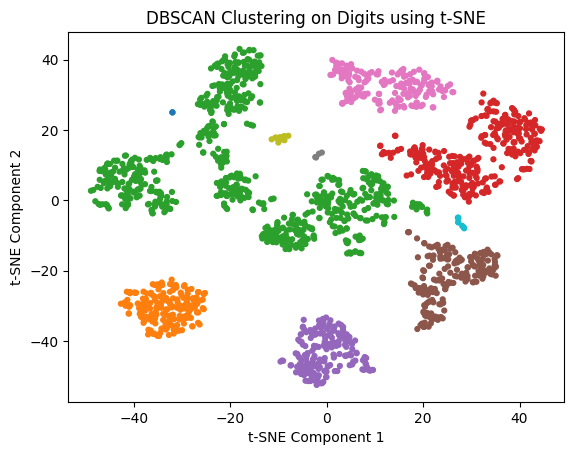

Noise points: 2


In [12]:
# TSNE: It is a powerful non-linear dimensionality reduction technique.
# Here, it maps the 64-dimensional standardized dataset (X_scaled)
# down into a 2-dimensional space (X_tsne) so that we can plot it on a standard 2D scatter plot.
from sklearn.manifold import TSNE

data = load_digits()
X = data.data

X_scaled = StandardScaler().fit_transform(X)

X_tsne = TSNE(
    n_components=2,
    random_state=42,
    init="pca",
    learning_rate="auto"
).fit_transform(X_scaled)

model = DBSCAN(eps=5, min_samples=5)
labels = model.fit_predict(X_tsne)

plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=labels, cmap="tab10", s=12
)

plt.title("DBSCAN Clustering on Digits using t-SNE")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.show()

print("Noise points:", sum(labels == -1))

Explanation: t-SNE reduces the original 64-dimensional data to two dimensions while attempting to preserve local neighborhood structure. DBSCAN then identifies dense groups and noise points.

Q33. Generate synthetic data using make_blobs and apply Agglomerative Clustering with complete linkage. Plot the result.

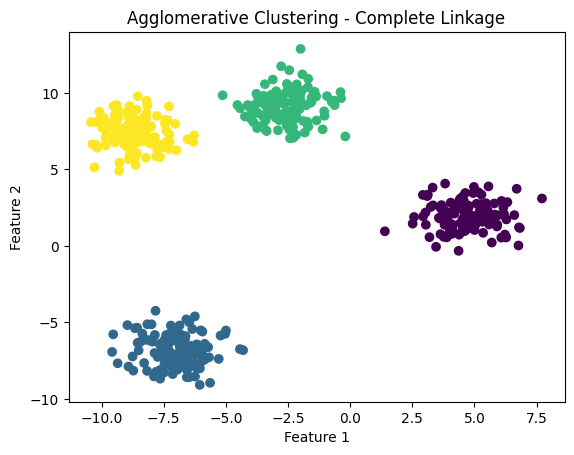

In [13]:
X, y = make_blobs(
    n_samples=500,
    centers=4,
    random_state=42
)

model = AgglomerativeClustering(
    n_clusters=4,
    linkage="complete"
)

labels = model.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.title("Agglomerative Clustering - Complete Linkage")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Explanation: Complete linkage calculates the maximum distance between observations in two clusters. The algorithm merges clusters based on this distance.

Q34. Load the Breast Cancer dataset and compare inertia values for K = 2 to 6 using K-Means. Show results in a line plot.

K=2, Inertia=11595.53
K=3, Inertia=10061.80
K=4, Inertia=9258.99
K=5, Inertia=8558.66
K=6, Inertia=7970.26


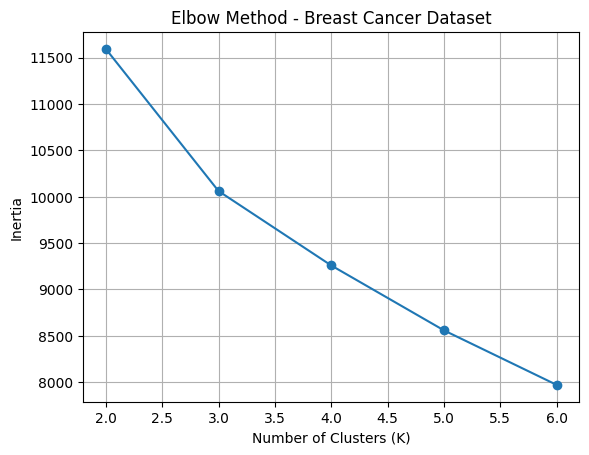

In [14]:
data = load_breast_cancer()
X = data.data

X_scaled = StandardScaler().fit_transform(X)

inertias = []
k_values = range(2, 7)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    # For each cluster, it calculates the squared distance between each data point in that cluster
    # and the cluster's centroid (the middle/mean of the cluster). It then sums these squared distances
    # across all points and all clusters.
    inertias.append(model.inertia_)

    print(f"K={k}, Inertia={model.inertia_:.2f}")

plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method - Breast Cancer Dataset")
plt.grid(True)
plt.show()

Explanation: The line plot shows how inertia changes as the number of clusters increases. The elbow method helps identify a reasonable cluster count.

Q35. Generate synthetic concentric circles using make_circles and cluster using Agglomerative Clustering with single linkage.

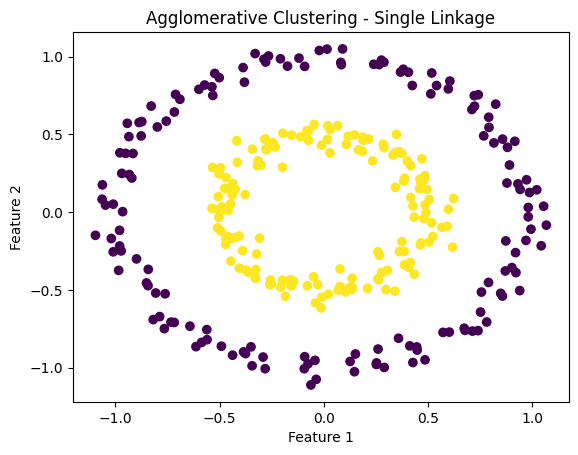

In [15]:
X, y = make_circles(
    n_samples=300,
    factor=0.5,
    noise=0.05,
    random_state=42
)

model = AgglomerativeClustering(
    n_clusters=2,
    linkage="single"
)

labels = model.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.title("Agglomerative Clustering - Single Linkage")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Explanation: Single linkage uses the minimum distance between two clusters. It can identify non-spherical shapes such as concentric circles.

Q36. Use the Wine dataset, apply DBSCAN after scaling the data, and count the number of clusters (excluding noise).

In [16]:
data = load_wine()
X = data.data

X_scaled = StandardScaler().fit_transform(X)

model = DBSCAN(eps=2.5, min_samples=5)
labels = model.fit_predict(X_scaled)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

Number of clusters: 1
Number of noise points: 24


Explanation: DBSCAN groups dense regions into clusters. The label -1 represents noise and is excluded when counting clusters.

Q37. Generate synthetic data with make_blobs and apply K-Means. Then plot the cluster centers on top of the data points.

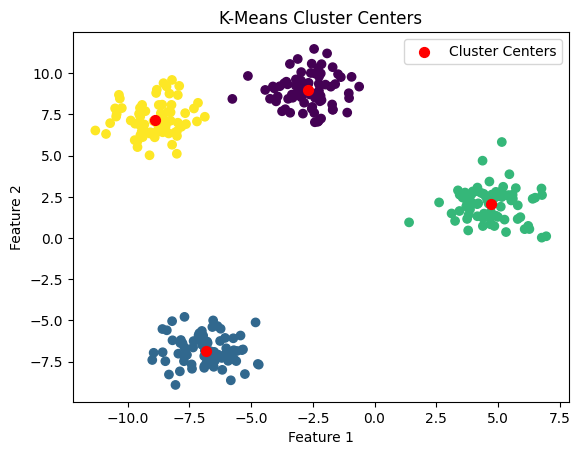

In [17]:
X, y = make_blobs(
    n_samples=300,
    centers=4,
    random_state=42
)

model = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = model.fit_predict(X)

centers = model.cluster_centers_

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color="red",
    marker=".",
    s=200,
    label="Cluster Centers"
)

plt.title("K-Means Cluster Centers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

Explanation: The scatter plot displays the assigned clusters, while red "o" markers represent the centroids calculated by K-Means.

Q38. Load the Iris dataset, cluster with DBSCAN, and print how many samples were identified as noise.

In [18]:
data = load_iris()
X = data.data

X_scaled = StandardScaler().fit_transform(X)

model = DBSCAN(eps=0.7, min_samples=5)
labels = model.fit_predict(X_scaled)

noise_count = np.sum(labels == -1)

print("Number of noise samples:", noise_count)
print("Cluster labels:", np.unique(labels))

Number of noise samples: 6
Cluster labels: [-1  0  1]


Explanation: DBSCAN identifies points that do not belong to any dense region. These points receive the label -1 and are counted as noise.

Q39. Generate synthetic non-linearly separable data using make_moons, apply K-Means, and visualize the clustering result.

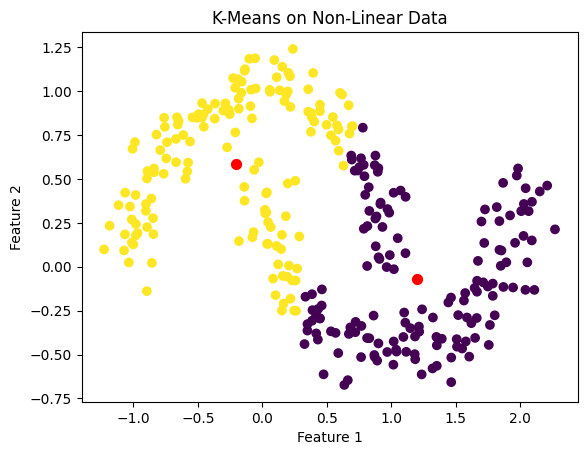

In [19]:
X, y = make_moons(
    n_samples=300,
    noise=0.1,
    random_state=42
)

model = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = model.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    color="red",
    marker=".",
    s=200
)

plt.title("K-Means on Non-Linear Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Explanation: K-Means attempts to divide the two moon-shaped groups using centroid-based distance. Because the clusters are non-linear, K-Means may not identify their natural shapes correctly.

Q40. Load the Digits dataset, apply PCA to reduce to 3 components, then use K-Means and visualize with a 3D scatter plot.

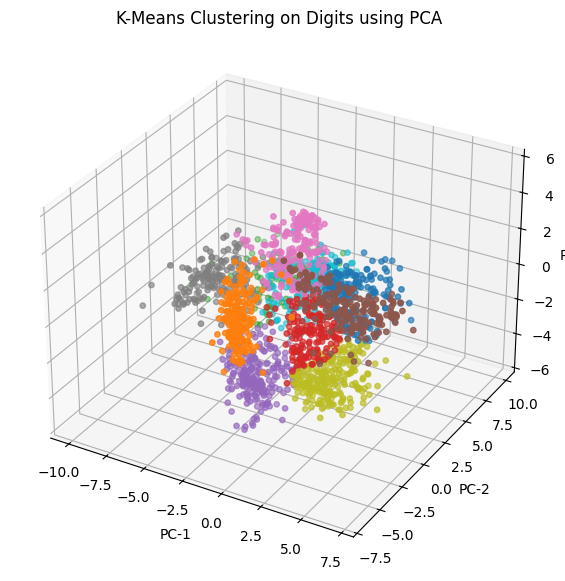

In [20]:
data = load_digits()
X = data.data

X_scaled = StandardScaler().fit_transform(X)
X_pca = PCA(n_components=3).fit_transform(X_scaled)

model = KMeans(n_clusters=10, random_state=42, n_init=10)
labels = model.fit_predict(X_pca)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    X_pca[:, 2],
    c=labels,
    cmap="tab10",
    s=15
)

ax.set_title("K-Means Clustering on Digits using PCA")
ax.set_xlabel("PC-1")
ax.set_ylabel("PC-2")
ax.set_zlabel("PC-3")

plt.show()

Explanation: PCA reduces the original 64 features to three principal components. K-Means creates ten clusters, which are displayed in a 3D scatter plot.

Q41. Generate synthetic blobs with 5 centers and apply K-Means. Then use silhouette_score to evaluate the clustering.

Silhouette Score: 0.6786441315351273


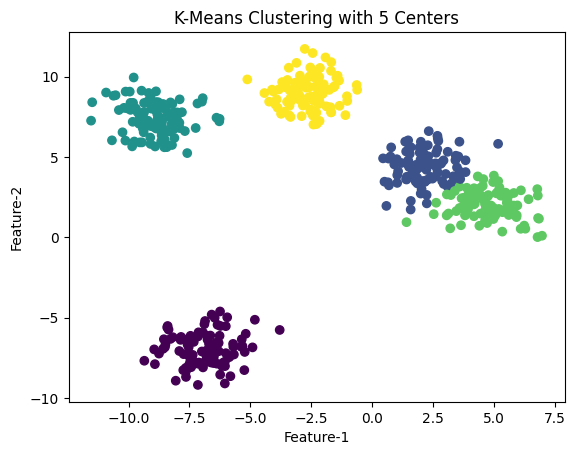

In [21]:
X, y = make_blobs(
    n_samples=500,
    centers=5,
    random_state=42
)

labels = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X)

score = silhouette_score(X, labels)

print("Silhouette Score:", score)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.title("K-Means Clustering with 5 Centers")
plt.xlabel("Feature-1")
plt.ylabel("Feature-2")
plt.show()

Explanation: The Silhouette Score measures how well the five clusters are separated. A higher score generally indicates better clustering quality.

Q42. Load the Breast Cancer dataset, reduce dimensionality using PCA, and apply Agglomerative Clustering. Visualize in 2D.

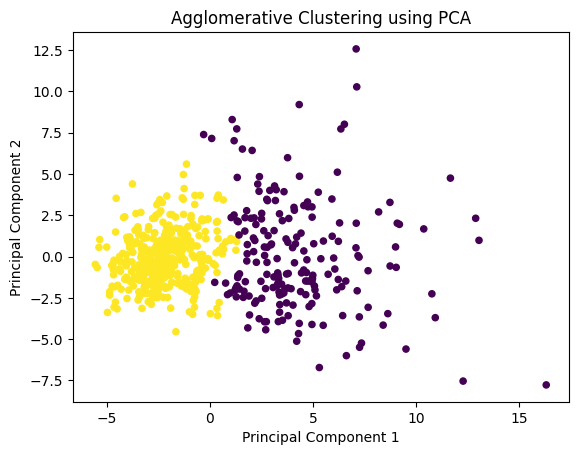

In [22]:
data = load_breast_cancer()
X = data.data

X_scaled = StandardScaler().fit_transform(X)

X_pca = PCA(n_components=2).fit_transform(X_scaled)

model = AgglomerativeClustering(n_clusters=2)
labels = model.fit_predict(X_pca)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="viridis",
    s=20
)

plt.title("Agglomerative Clustering using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

Explanation: PCA reduces the dataset to two dimensions. Agglomerative Clustering then divides the transformed observations into two clusters.

Q43. Generate noisy circular data using make_circles and visualize clustering results from K-Means and DBSCAN side-by-side.

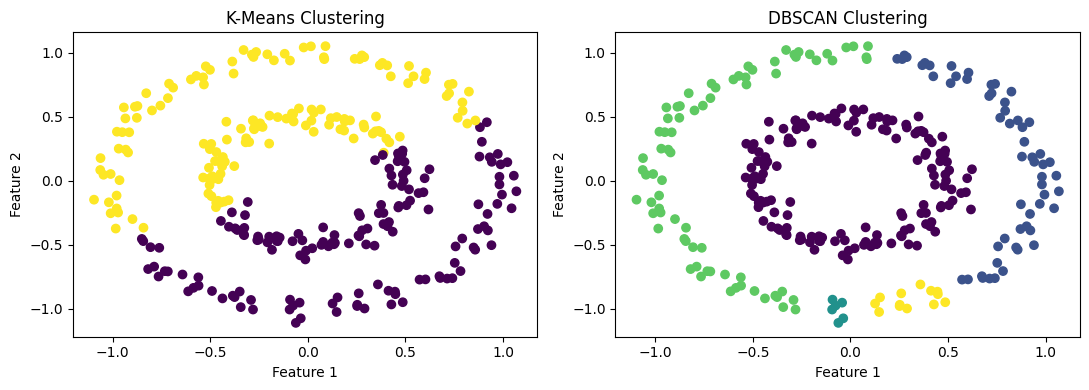

In [23]:
X, y = make_circles(
    n_samples=300,
    factor=0.5,
    noise=0.05,
    random_state=42
)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

dbscan = DBSCAN(eps=0.15, min_samples=5)
dbscan_labels = dbscan.fit_predict(X)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(
    X[:, 0], X[:, 1],
    c=kmeans_labels, cmap="viridis"
)
axes[0].set_title("K-Means Clustering")

axes[1].scatter(
    X[:, 0], X[:, 1],
    c=dbscan_labels, cmap="viridis"
)
axes[1].set_title("DBSCAN Clustering")

for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

Explanation: K-Means groups points around centroids, while DBSCAN groups points based on density. DBSCAN is generally more suitable for identifying the two concentric circular clusters.

Q44. Load the Iris dataset and plot the Silhouette Coefficient for each sample after K-Means clustering.

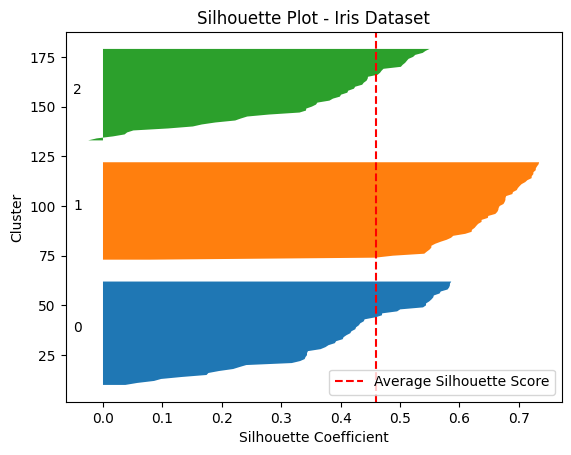

Average Silhouette Score: 0.45994823920518635


In [24]:
from sklearn.metrics import silhouette_samples

data = load_iris()
X = data.data

X_scaled = StandardScaler().fit_transform(X)

model = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = model.fit_predict(X_scaled)

sample_scores = silhouette_samples(X_scaled, labels)

y_lower = 10

for cluster in range(3):
    scores = sample_scores[labels == cluster]
    scores.sort()

    size = len(scores)
    y_upper = y_lower + size

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        scores
    )

    plt.text(-0.05, y_lower + size / 2, str(cluster))
    y_lower = y_upper + 10

plt.axvline(
    np.mean(sample_scores),
    color="red",
    linestyle="--",
    label="Average Silhouette Score"
)

plt.xlabel("Silhouette Coefficient")
plt.ylabel("Cluster")
plt.title("Silhouette Plot - Iris Dataset")
plt.legend()
plt.show()

print("Average Silhouette Score:", np.mean(sample_scores))

Explanation: silhouette_samples() calculates a Silhouette Coefficient for every observation. The plot shows how well individual samples fit within their assigned clusters.

Q45. Generate synthetic data using make_blobs and apply Agglomerative Clustering with average linkage. Visualize clusters.

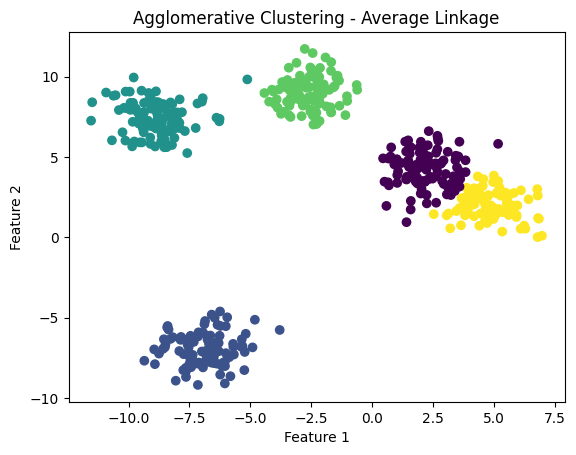

In [25]:
X, y = make_blobs(
    n_samples=500,
    centers=5,
    random_state=42
)

model = AgglomerativeClustering(
    n_clusters=5,
    linkage="average"
)

labels = model.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")

plt.title("Agglomerative Clustering - Average Linkage")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Explanation: Average linkage calculates the average distance between all pairs of points in two clusters. The algorithm merges clusters based on this distance.

Q46. Load the Wine dataset, apply K-Means, and visualize the cluster assignments in a Seaborn pairplot (first 4 features).

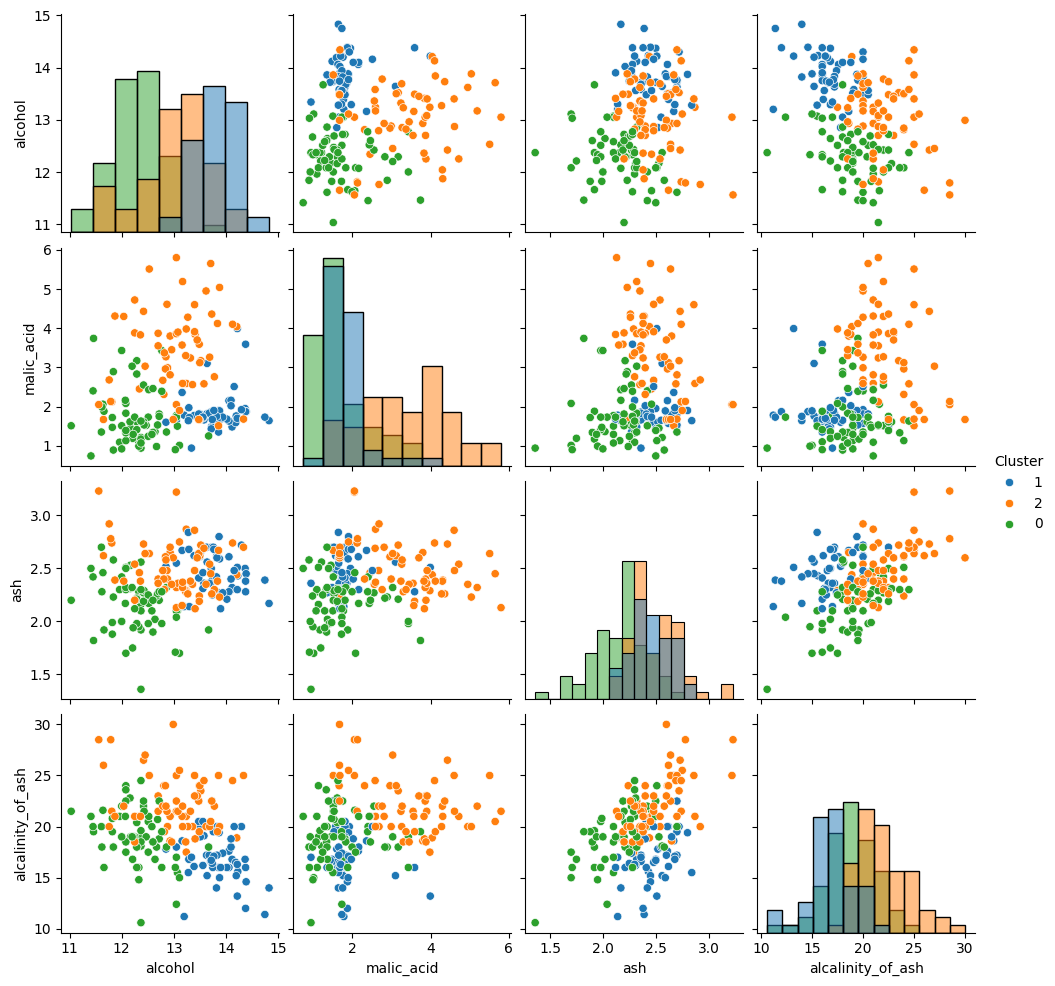

In [27]:
import seaborn as sns
import pandas as pd

data = load_wine()

X = data.data[:, :4]

X_scaled = StandardScaler().fit_transform(X)

model = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = model.fit_predict(X_scaled)

df = pd.DataFrame(
    X,
    columns=data.feature_names[:4]
)

df["Cluster"] = labels.astype(str)

sns.pairplot(
    df,
    hue="Cluster",
    diag_kind="hist"
)

plt.show()

Explanation: The first four Wine features are selected and standardized before K-Means clustering. Seaborn's pairplot displays pairwise relationships between features, with colors representing cluster assignments.

Q47. Generate noisy blobs using make_blobs and use DBSCAN to identify both clusters and noise points. Print the count.

Number of clusters: 3
Number of noise points: 31


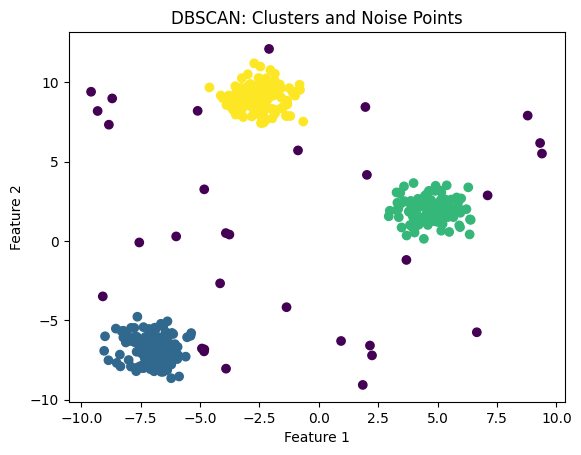

In [28]:
X, y = make_blobs(
    n_samples=400,
    centers=3,
    cluster_std=0.8,
    random_state=42
)

# Add random noise points
rng = np.random.RandomState(42)
# rng.uniform(low, high, ...): Generates random numbers from a uniform distribution,
# meaning any value between -10 and 10 has an equal chance of being selected.
noise = rng.uniform(
    low=-10,
    high=10,
    size=(30, 2)
)

# np.vstack (Vertical Stack): Appends the newly generated noise points to the bottom of your original cluster dataset X.
X = np.vstack([X, noise])

model = DBSCAN(eps=0.8, min_samples=5)
labels = model.fit_predict(X)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.title("DBSCAN: Clusters and Noise Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Explanation: The program creates three dense clusters and adds 30 randomly distributed points. DBSCAN identifies clusters and marks points that do not belong to dense regions with -1.

Q48. Load the Digits dataset, reduce dimensions using t-SNE, then apply Agglomerative Clustering and plot the clusters.

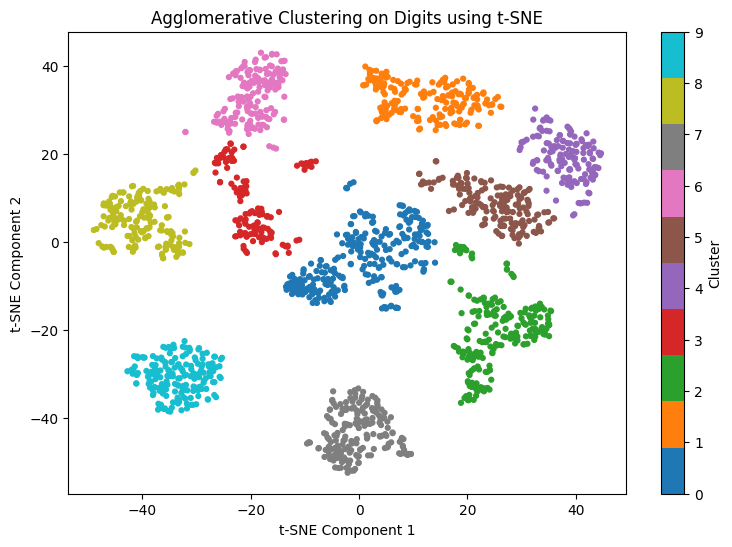

In [29]:
data = load_digits()
X = data.data

X_scaled = StandardScaler().fit_transform(X)

# Tells t-SNE to reduce the high-dimensional feature space (which has 64 dimensions for the Digits dataset) down to a 2-dimensional
# target space. This gives each digit image a set of 2D coordinates (X and Y) suitable for plotting on a scatter plot.
X_tsne = TSNE(
    n_components=2,
    random_state=42,
    # init="pca": This controls how the points are initially placed in the 2D space before the optimization step begins.
    # Using PCA (Principal Component Analysis) initialization is highly recommended.
    init="pca",
    learning_rate="auto"
).fit_transform(X_scaled)

model = AgglomerativeClustering(n_clusters=10)
labels = model.fit_predict(X_tsne)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=labels,
    cmap="tab10",
    s=12
)

plt.title("Agglomerative Clustering on Digits using t-SNE")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.colorbar(label="Cluster")
plt.show()

Explanation: t-SNE converts the original 64-dimensional digit data into two dimensions. Agglomerative Clustering groups the transformed observations into ten clusters, which are visualized using a scatter plot.